# 01 — Simulación fundamentada y verificación de los datos
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AlejandroP212/ML2-Proyecto-Riesgo-Crediticio/blob/main/notebooks/01_simulacion_y_verificacion.ipynb)

**Integrantes:** David Castro & Alejandro Pardo
**Asignatura:** Machine Learning II — Universidad Externado de Colombia

> Notebook de reproducibilidad creado después de la entrega (noviembre de 2026). Los archivos entregados el
> 02/10/2026 están sin modificaciones en `entregas/entrega_2/`.

Corresponde a la sección **7.1 Consolidación de los datos** del enunciado. El notebook:

1. **Construye la simulación paso a paso**, con el código completo de cada variable y la justificación de su
   distribución, sus parámetros y su fuente (secciones 1–2).
2. Comprueba que el resultado es **idéntico byte a byte** al dataset usado en la entrega (sección 3).
3. Verifica que los datos reproducen la estructura prevista: proporciones, distribuciones, relaciones y nulos (secciones 4–7).

El mismo código está en `src/simulacion_credito.py` como módulo reutilizable.

In [1]:
# === Configuración de rutas (funciona en Colab y en local) ===
import os, sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("ML2-Proyecto-Riesgo-Crediticio").exists():
    !git clone -q https://github.com/AlejandroP212/ML2-Proyecto-Riesgo-Crediticio.git
    os.chdir("ML2-Proyecto-Riesgo-Crediticio")

ROOT = Path.cwd()
while not (ROOT / "CHECKSUMS.txt").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
DATA, FIGS, TABLES = ROOT / "data", ROOT / "figuras", ROOT / "resultados"
for d in (DATA, FIGS, TABLES):
    d.mkdir(exist_ok=True)
SEED = 42
print("Raíz del proyecto encontrada:", ROOT.name)

Raíz del proyecto encontrada: ml2-proyecto-riesgo-crediticio


In [2]:
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Diseño de la simulación

La simulación no asigna valores al azar de forma independiente: **el tipo de empleo condiciona a casi todas
las demás variables**, y la mora se deriva de ellas. La cadena generadora es:

> informalidad → menor ingreso, menor antigüedad, más moras previas y peor score → mayor relación cuota/ingreso
> → mayor probabilidad de incumplimiento

| Variable | Distribución | Informal / formal | Fundamento |
|---|---|---|---|
| `es_informal` | Bernoulli(p = 0,545) | — | Informalidad laboral, DANE, abril-junio de 2026 |
| `edad` | Uniforme entera [18, 69] | igual | Variable de control: **no** afecta la mora |
| `antiguedad_laboral` | Exponencial (media) | 2,0 / 5,5 años | Muchos con poca antigüedad; mayor rotación en el sector informal |
| `ingreso_smmlv` | Lognormal (mediana = e^μ) | e^0,55 ≈ 1,7 / e^1,10 ≈ 3,0 | Ingreso positivo con cola larga; brecha salarial por tipo de empleo |
| `monto_credito_smmlv` | Lognormal | mediana e^1,4 ≈ 4,1 | Montos positivos y asimétricos |
| `plazo_meses` | Uniforme sobre {12, 24, 36, 48, 60} | igual | Plazos comerciales típicos |
| `creditos_activos` | Poisson(λ = 1,4) | igual | Conteo; **no** afecta la mora |
| `moras_previas` | Poisson | λ = 0,75 / 0,25 | Conteo de eventos poco frecuentes |
| `score_crediticio` | Normal truncada a [300, 850] | 585 / 675 | Rango de los burós; menor bancarización informal |
| `relacion_cuota_ingreso` | Derivada | — | (monto / plazo × 1,2) / ingreso: capacidad de pago |
| `incumple` | Logit latente + corte al 8,5 % | — | Cartera vencida 3,8 % (Superfinanciera, marzo de 2026), ajustada al alza por informalidad |

**Semilla:** se fija `np.random.seed(42)` una sola vez y las llamadas aleatorias se hacen siempre en el mismo orden.
Así cualquier persona obtiene exactamente los mismos 6.000 registros.

## 2. Código de la simulación, paso a paso

### 2.1 Semilla, edad e informalidad
- `edad`: uniforme entre 18 y 69 años. Se incluye a propósito **sin efecto** sobre la mora, para comprobar
  después que el modelo no le asigna importancia.
- `es_informal`: Bernoulli con p = 0,545 (DANE).

In [3]:
N = 6000
np.random.seed(SEED)

edad = np.random.randint(18, 70, size=N)
es_informal = np.random.choice([1, 0], size=N, p=[0.545, 0.455])

print(f"Informales: {es_informal.mean():.2%}")

Informales: 56.45%


### 2.2 Antigüedad laboral ~ Exponencial
El parámetro `scale` de NumPy es la **media** de la exponencial (equivale a 1/λ): 2,0 años para informales y
5,5 para formales. La exponencial produce muchos valores pequeños y pocos grandes, como la permanencia en un empleo.

*Detalle técnico:* `np.where` evalúa las dos ramas, así que se generan 6.000 valores de cada distribución y luego
se elige cuál conservar para cada persona.

In [4]:
antiguedad = np.where(
    es_informal == 1,
    np.random.exponential(scale=2.0, size=N),   # informal: media 2,0 años
    np.random.exponential(scale=5.5, size=N),   # formal:   media 5,5 años
).round(1)

### 2.3 Ingreso mensual ~ Lognormal (en salarios mínimos)
En NumPy, `mean` y `sigma` son la media y la desviación del **logaritmo** del ingreso, por lo que la mediana del
ingreso es e^mean: ≈ 1,7 SMMLV para informales y ≈ 3,0 SMMLV para formales. La lognormal solo produce valores
positivos y tiene cola larga a la derecha (pocas personas con ingresos muy altos).

In [5]:
ingreso_smmlv = np.where(
    es_informal == 1,
    np.random.lognormal(mean=0.55, sigma=0.45, size=N),   # mediana e^0,55 ≈ 1,73
    np.random.lognormal(mean=1.10, sigma=0.55, size=N),   # mediana e^1,10 ≈ 3,00
).round(2)

### 2.4 Crédito solicitado
- Monto ~ Lognormal con mediana e^1,4 ≈ 4,1 SMMLV (igual para ambos segmentos).
- Plazo: uno de cinco plazos comerciales, con la misma probabilidad.

In [6]:
monto_credito_smmlv = np.random.lognormal(mean=1.4, sigma=0.65, size=N).round(2)
plazo_meses = np.random.choice([12, 24, 36, 48, 60], size=N)

### 2.5 Historial crediticio ~ Poisson
La Poisson modela conteos de eventos poco frecuentes en un periodo.
- `creditos_activos`: media 1,4 para todos. **No** entra en la fórmula de la mora (segunda variable de control).
- `moras_previas`: media 0,75 para informales frente a 0,25 para formales.

In [7]:
creditos_activos = np.random.poisson(lam=1.4, size=N)
moras_previas = np.where(
    es_informal == 1,
    np.random.poisson(lam=0.75, size=N),
    np.random.poisson(lam=0.25, size=N),
)

### 2.6 Score crediticio ~ Normal truncada a [300, 850]
Media 585 (σ = 75) para informales y 675 (σ = 70) para formales; los valores fuera del rango de los burós se
recortan a 300 u 850.

In [8]:
score_crediticio = np.where(
    es_informal == 1,
    np.random.normal(loc=585, scale=75, size=N),
    np.random.normal(loc=675, scale=70, size=N),
).clip(300, 850).round(0)

### 2.7 Capacidad de pago: relación cuota/ingreso
Cuota mensual aproximada = (monto / plazo) × 1,2, donde el factor 1,2 representa los intereses. Se divide entre el
ingreso, con un piso de 0,5 SMMLV para evitar relaciones extremas en ingresos muy bajos.

In [9]:
cuota_estimada_smmlv = (monto_credito_smmlv / plazo_meses) * 1.2
relacion_cuota_ingreso = (cuota_estimada_smmlv / np.maximum(ingreso_smmlv, 0.5)).round(3)

### 2.8 Variable objetivo: logit latente de incumplimiento
La probabilidad de mora combina los factores de riesgo en una regresión logística latente. Los coeficientes son
**supuestos del equipo**: fijan la dirección y el tamaño relativo de cada efecto (no se estimaron con datos reales).
Leídos como cambio en las *odds* (probabilidad de mora / probabilidad de pago):

| Término | Coeficiente | Efecto sobre las odds de mora |
|---|---|---|
| Intercepto | −2,40 | Nivel base de riesgo |
| Informal | +0,80 | × e^0,80 ≈ 2,2 |
| Relación cuota/ingreso | +1,30 | +0,1 en la relación → × 1,14 |
| Antigüedad laboral (años) | −0,10 | cada año → × 0,90 |
| Score − 600 | −0,007 | +100 puntos → × 0,50 |
| Moras previas | +0,50 | cada mora → × 1,65 |
| Ingreso (SMMLV) | −0,12 | +1 SMMLV → × 0,89 |
| Ruido N(0; 0,45) | — | Heterogeneidad no observada |

`edad`, `plazo_meses` (salvo a través de la cuota) y `creditos_activos` no entran en la fórmula.

**Corte al 8,5 %:** se marca como `incumple = 1` al 8,5 % de solicitantes con mayor probabilidad (percentil 91,5).
Así la prevalencia queda exactamente en 8,5 %. Es un corte determinista, no un sorteo, y por eso la mora se
concentra en los perfiles de mayor riesgo (ver sección 5).

In [10]:
logit = (
    - 2.40
    + 0.80 * es_informal
    + 1.30 * relacion_cuota_ingreso
    - 0.10 * antiguedad
    - 0.007 * (score_crediticio - 600)
    + 0.50 * moras_previas
    - 0.12 * ingreso_smmlv
    + np.random.normal(0, 0.45, size=N)
)
prob_incumplimiento = 1 / (1 + np.exp(-logit))
incumple = (prob_incumplimiento > np.percentile(prob_incumplimiento, 91.5)).astype(int)

print(f"Prevalencia de mora: {incumple.mean():.2%}")

Prevalencia de mora: 8.50%


### 2.9 Tabla final y valores faltantes (MCAR)
Los faltantes se introducen **completamente al azar** (MCAR) y **después** de calcular la mora, de modo que la mora
depende de los valores completos. Su objetivo es exigir imputación en el preprocesamiento: ingreso 4 %,
antigüedad 5 % y score 3 %.

In [11]:
df = pd.DataFrame({
    "edad": edad,
    "es_informal": es_informal,
    "antiguedad_laboral": antiguedad,
    "ingreso_smmlv": ingreso_smmlv,
    "monto_credito_smmlv": monto_credito_smmlv,
    "plazo_meses": plazo_meses,
    "creditos_activos": creditos_activos,
    "moras_previas": moras_previas,
    "score_crediticio": score_crediticio,
    "relacion_cuota_ingreso": relacion_cuota_ingreso,
    "incumple": incumple,
})

df.loc[np.random.rand(N) < 0.04, "ingreso_smmlv"] = np.nan
df.loc[np.random.rand(N) < 0.05, "antiguedad_laboral"] = np.nan
df.loc[np.random.rand(N) < 0.03, "score_crediticio"] = np.nan

ruta = DATA / "credito_colombia_simulado.csv"
df.to_csv(ruta, index=False)
print("Dataset guardado en", ruta.relative_to(ROOT), df.shape)
df.head()

Dataset guardado en data/credito_colombia_simulado.csv (6000, 11)


,edad,es_informal,antiguedad_laboral,ingreso_smmlv,monto_credito_smmlv,plazo_meses,creditos_activos,moras_previas,score_crediticio,relacion_cuota_ingreso,incumple
0,56,1,0.4,1.70,2.39,12,0,1,541.0,0.141,0
1,69,0,1.3,2.31,3.46,12,1,0,649.0,0.150,0
2,46,1,0.3,2.16,2.54,36,2,0,726.0,0.039,0
3,32,0,8.4,1.58,8.05,12,2,0,716.0,0.509,0
4,60,1,1.3,0.75,4.28,60,0,1,532.0,0.114,0


## 3. Verificación de reproducibilidad
El archivo construido aquí, el que produce el módulo `src/simulacion_credito.py` y el CSV original de la entrega
deben tener el mismo hash SHA-256.

In [12]:
from src.simulacion_credito import generar_dataset_credito_colombia

def sha256(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()

ruta_modulo = DATA / "_verificacion_modulo.csv"
generar_dataset_credito_colombia(n_samples=N, seed=SEED).to_csv(ruta_modulo, index=False)

hashes = {
    "Este notebook": sha256(ruta),
    "src/simulacion_credito.py": sha256(ruta_modulo),
    "Original de la entrega": sha256(ROOT / "entregas/entrega_2/datasets/credito_colombia_simulado.csv"),
}
ruta_modulo.unlink()
for k, v in hashes.items():
    print(f"{k:28s} {v}")
assert len(set(hashes.values())) == 1, "Los datasets NO coinciden"
print("✔ Los tres archivos son idénticos.")

Este notebook                59ab694c48a96c7979508acbca426a90066cbbfbf1e4928a1eb23d7c128a9347
src/simulacion_credito.py    59ab694c48a96c7979508acbca426a90066cbbfbf1e4928a1eb23d7c128a9347
Original de la entrega       59ab694c48a96c7979508acbca426a90066cbbfbf1e4928a1eb23d7c128a9347
✔ Los tres archivos son idénticos.


## 4. Verificación de la estructura simulada
Se contrastan las proporciones y medianas obtenidas con los parámetros de calibración declarados en el informe (Cuadro 1).

In [13]:
inf, form = df[df.es_informal == 1], df[df.es_informal == 0]
verif = pd.DataFrame([
    ("Tasa de informalidad", "54.5 % (DANE)", f"{df.es_informal.mean():.2%}"),
    ("Tasa de incumplimiento", "8.5 %", f"{df.incumple.mean():.2%}"),
    ("Mediana ingreso informal (SMMLV)", "≈ e^0.55 = 1.73", f"{inf.ingreso_smmlv.median():.2f}"),
    ("Mediana ingreso formal (SMMLV)", "≈ e^1.10 = 3.00", f"{form.ingreso_smmlv.median():.2f}"),
    ("Media antigüedad informal (años)", "2.0", f"{inf.antiguedad_laboral.mean():.2f}"),
    ("Media antigüedad formal (años)", "5.5", f"{form.antiguedad_laboral.mean():.2f}"),
    ("Media score informal", "585", f"{inf.score_crediticio.mean():.0f}"),
    ("Media score formal", "675", f"{form.score_crediticio.mean():.0f}"),
    ("Media moras previas informal", "0.75", f"{inf.moras_previas.mean():.2f}"),
    ("Media moras previas formal", "0.25", f"{form.moras_previas.mean():.2f}"),
    ("Mediana monto crédito (SMMLV)", "≈ e^1.4 = 4.06", f"{df.monto_credito_smmlv.median():.2f}"),
], columns=["Característica", "Valor teórico", "Valor simulado"])
verif.to_csv(TABLES / "verificacion_simulacion.csv", index=False)
verif

,Característica,Valor teórico,Valor simulado
0,Tasa de informalidad,54.5 % (DANE),56.45%
1,Tasa de incumplimiento,8.5 %,8.50%
2,Mediana ingreso informal (SMMLV),≈ e^0.55 = 1.73,1.75
3,Mediana ingreso formal (SMMLV),≈ e^1.10 = 3.00,3.05
4,Media antigüedad informal (años),2.0,2.04
5,Media antigüedad formal (años),5.5,5.71
6,Media score informal,585,586
7,Media score formal,675,675
8,Media moras previas informal,0.75,0.75
9,Media moras previas formal,0.25,0.26


Todos los valores simulados quedan cerca de su valor teórico, salvo la informalidad: con la semilla 42 la muestra
quedó en **56,45 %**, unos 3 errores estándar por encima de 0,545 (error estándar ≈ 0,64 puntos con n = 6.000).
Se conserva así para no alterar el dataset entregado.

## 5. Tasa de incumplimiento por segmento
La simulación debe reflejar la prima de riesgo del segmento informal.

In [14]:
seg = df.groupby("es_informal")["incumple"].agg(["mean", "sum", "count"]).rename(
    index={0: "Formal", 1: "Informal"}, columns={"mean": "tasa_mora", "sum": "morosos", "count": "n"})
seg

,tasa_mora,morosos,n
es_informal,,,
Formal,0.000765,2,2613
Informal,0.149985,508,3387


**Lectura y limitación.** La prima de riesgo informal se cumple, pero de forma extrema: casi todos los morosos son
informales y la mora formal es prácticamente nula. Se debe a la combinación de efectos que van en la misma dirección
(informalidad, menor score, más moras y menor ingreso) con el **corte determinista** al 8,5 %: solo los perfiles de
mayor riesgo superan el umbral, y casi todos son informales. En datos reales la mora formal no es cero, por lo que
`es_informal` resulta aquí más discriminante de lo que sería en la práctica. Se documenta como limitación de la
simulación.

## 6. Calidad de los datos (nulos introducidos MCAR)

In [15]:
nulos = pd.DataFrame({"nulos": df.isna().sum(), "porcentaje": df.isna().mean().mul(100).round(2)})
nulos[nulos.nulos > 0]

,nulos,porcentaje
antiguedad_laboral,287,4.78
ingreso_smmlv,241,4.02
score_crediticio,179,2.98


## 7. Figuras 1 y 2 del informe

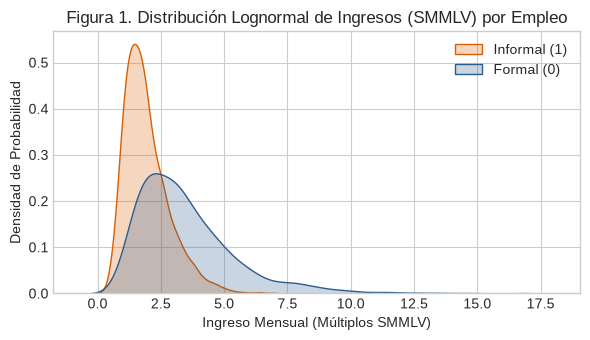

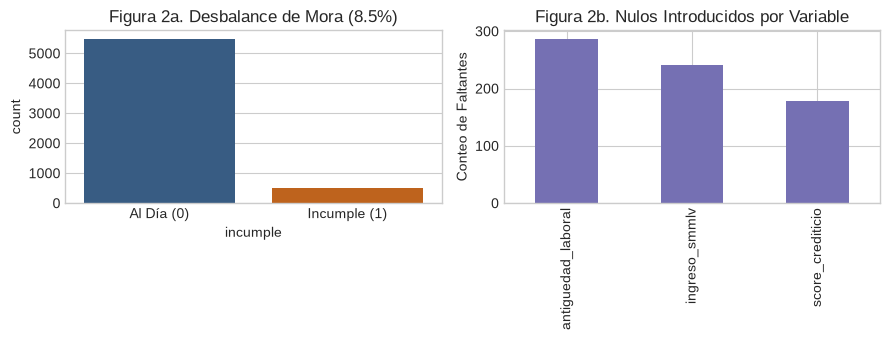

In [16]:
plt.style.use("seaborn-v0_8-whitegrid")
AZUL, NARANJA = "#2b5c8f", "#d95f02"

fig, ax = plt.subplots(figsize=(6, 3.5))
sns.kdeplot(data=df, x="ingreso_smmlv", hue="es_informal", fill=True, common_norm=False,
            palette={1: NARANJA, 0: AZUL}, ax=ax)
ax.legend(["Informal (1)", "Formal (0)"])
ax.set(title="Figura 1. Distribución Lognormal de Ingresos (SMMLV) por Empleo",
       xlabel="Ingreso Mensual (Múltiplos SMMLV)", ylabel="Densidad de Probabilidad")
plt.tight_layout(); plt.savefig(FIGS / "fig1_distribucion_ingresos.png", dpi=300); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
sns.countplot(data=df, x="incumple", hue="incumple", palette=[AZUL, NARANJA], legend=False, ax=ax[0])
ax[0].set_xticks([0, 1], ["Al Día (0)", "Incumple (1)"])
ax[0].set_title(f"Figura 2a. Desbalance de Mora ({df.incumple.mean():.1%})")
n = df.isna().sum(); n[n > 0].plot(kind="bar", color="#7570b3", ax=ax[1])
ax[1].set(title="Figura 2b. Nulos Introducidos por Variable", ylabel="Conteo de Faltantes")
plt.tight_layout(); plt.savefig(FIGS / "fig2_diagnostico_nulos_desbalance.png", dpi=300); plt.show()

## 8. Relaciones entre variables
Correlaciones esperadas por construcción: informalidad ↔ menor score, ingreso y antigüedad, y más moras previas.
`edad` y `creditos_activos` no deben correlacionar con `incumple`.

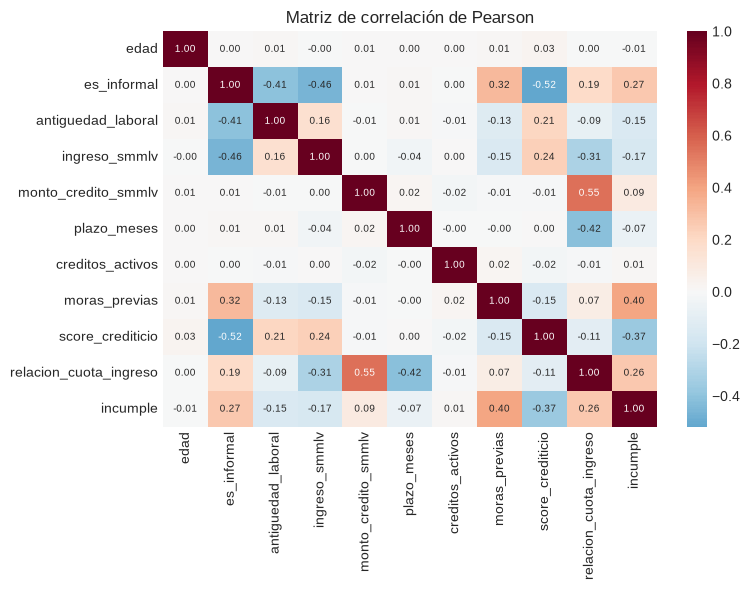

In [17]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, annot_kws={"size": 7})
ax.set_title("Matriz de correlación de Pearson")
plt.tight_layout(); plt.savefig(FIGS / "correlaciones.png", dpi=200); plt.show()